**Part 1) i) Collect daily stock market price of 10 different stocks from 10 different industries (for
example: Oil, Renewable Energy, core Banking, Metals, Commodities, Real estate, software
Service, manufacturing, Power, NBFC etc) for the last 2 years.**

In [25]:
try:
  import yfinance
  print("Library 'yfinance' is installed.")
except ModuleNotFoundError:
  print("Library 'yfinance' is not installed.")

Library 'yfinance' is installed.


In [26]:
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import datetime

Choosing 10 stocks from different indurtries

In [27]:
stocks = [
    'RELIANCE.NS',   # Energy / Oil
    'TATAPOWER.NS',  # Power / Renewable
    'SBIN.NS',       # Banking
    'TATASTEEL.NS',  # Metals
    'COALINDIA.NS',  # Commodities / Mining
    'DLF.NS',        # Real estate
    'INFY.NS',       # IT / Software
    'LT.NS',         # Manufacturing / Engineering (Larsen & Toubro)
    'POWERGRID.NS',  # Power transmission
    'BAJAJFINSV.NS'  # NBFC / Financials
]
index_ticker = '^NSEI'  # Nifty50 index ticker on Yahoo Finance

Downloading 2 years of daily close prices

In [28]:
#end = datetime.date.today()
#start = end - datetime.timedelta(days=2*365)  # roughly 2 years

all_tickers = stocks + [index_ticker]

raw_data = yf.download(all_tickers, start='2023-09-28', end='2025-09-28', progress=False)
# result: DataFrame with columns = tickers, index = Date
data = raw_data['Close'].copy()
data = data.sort_index()
print("Downloaded shape:", data.shape)
data.head()

/tmp/ipython-input-478376369.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(all_tickers, start='2023-09-28', end='2025-09-28', progress=False)


Downloaded shape: (494, 11)


Ticker,BAJAJFINSV.NS,COALINDIA.NS,DLF.NS,INFY.NS,LT.NS,POWERGRID.NS,RELIANCE.NS,SBIN.NS,TATAPOWER.NS,TATASTEEL.NS,^NSEI
Date,,,,,,,,,,,
2023-09-28,1537.979858,250.990311,513.389404,1366.150146,2958.927490,186.380127,1158.475708,568.798706,255.357529,121.463135,19523.550781
2023-09-29,1538.529297,255.314758,524.050049,1362.353760,2972.247559,185.451721,1163.885620,577.090332,259.563171,123.474739,19638.300781
2023-10-03,1559.306030,252.460556,531.798828,1360.977661,3021.104248,185.266022,1150.559204,581.332581,261.196014,122.612625,19528.750000
2023-10-04,1530.837891,249.044312,518.966553,1370.800537,2976.376221,184.755402,1148.573853,565.231323,253.972137,120.026268,19436.099609
2023-10-05,1540.826782,250.255142,518.226196,1388.927979,3043.517334,182.527206,1148.549194,570.919861,255.110138,119.978371,19545.750000


Feature Engineering

**Part 1) ii) Use support vector classifier (SVC) to predict the stock buying behaviour of each stock and
compare the cumulative returns from the SVC to actual cumulative returns for each stock.**

In [29]:
def compute_features(prices: pd.Series) -> pd.DataFrame:
    df = pd.DataFrame(index=prices.index)
    df['price'] = prices
    df['ret_1d'] = prices.pct_change(1)   #1 day return
    df['ret_5d'] = prices.pct_change(5)   #5 day return
    df['ret_10d'] = prices.pct_change(10)   #10 day return
    df['sma_20'] = prices.rolling(20).mean()    #20 day Moving average
    df['sma_ratio'] = prices / df['sma_20']   #SMA ratio captures mean-reversion signals
    df['vol_20'] = df['ret_1d'].rolling(20).std()   # 20-day volatility (risk)

    # RSI (14) (Relative Strength Index, momentum indicator)
    delta = prices.diff()
    up = delta.clip(lower=0)
    down = -delta.clip(upper=0)
    ma_up = up.rolling(window=14, min_periods=14).mean()
    ma_down = down.rolling(window=14, min_periods=14).mean()
    rs = ma_up / ma_down
    df['rsi_14'] = 100 - (100 / (1 + rs))

    # target: next day return -> is tomorrow’s return positive? (1 = buy, 0 = don't buy)
    df['next_ret'] = prices.pct_change().shift(-1)
    df['target'] = (df['next_ret'] > 0).astype(int)

    # drop rows with NA in features or target
    df = df.dropna()
    return df

Train test split

In [30]:
from collections import defaultdict

results_per_stock = {}
np.random.seed(42)

for ticker in stocks:
    prices = data[ticker].dropna()
    df = compute_features(prices)
    if df.empty or len(df) < 100:
        print(f"Not enough data for {ticker}, skipping.")
        continue

    # 80% train, 20% test (time split)
    split_idx = int(len(df) * 0.8)
    train = df.iloc[:split_idx]
    test = df.iloc[split_idx:]

    # Features we use
    features = ['ret_1d','ret_5d','ret_10d','sma_ratio','vol_20','rsi_14']

    X_train, y_train = train[features].values, train['target'].values
    X_test, y_test = test[features].values, test['target'].values

    # Pipeline = standardize features + SVC classifier
    clf = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale'))
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    # Store results
    test = test.copy()
    test['pred'] = y_pred
    test['true'] = y_test

    rep = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)

    results_per_stock[ticker] = {
        'train_len': len(train),
        'test_len': len(test),
        'test_df': test,
        'clf': clf,
        'classification_report': rep,
        'confusion_matrix': cm
    }

    print(f"Ticker {ticker}: test len {len(test)}; accuracy: {rep['accuracy']:.3f}")

Ticker RELIANCE.NS: test len 95; accuracy: 0.526
Ticker TATAPOWER.NS: test len 95; accuracy: 0.611
Ticker SBIN.NS: test len 95; accuracy: 0.484
Ticker TATASTEEL.NS: test len 95; accuracy: 0.474
Ticker COALINDIA.NS: test len 95; accuracy: 0.516
Ticker DLF.NS: test len 95; accuracy: 0.547
Ticker INFY.NS: test len 95; accuracy: 0.516
Ticker LT.NS: test len 95; accuracy: 0.442
Ticker POWERGRID.NS: test len 95; accuracy: 0.495
Ticker BAJAJFINSV.NS: test len 95; accuracy: 0.516


5) Strategy vs Buy-and-Hold

In [31]:
def compute_strategy_vs_hold(test_df):
    # If model says BUY (pred==1), we earn tomorrow’s return; else 0
    strat_daily = test_df['pred'] * test_df['next_ret']
    strat_daily = strat_daily.fillna(0)

    strat_cum = (1 + strat_daily).cumprod() - 1
    hold_cum = (test_df['price'] / test_df['price'].iloc[0]) - 1

    return strat_cum, hold_cum

for ticker, info in results_per_stock.items():
    test_df = info['test_df']
    strat_cum, hold_cum = compute_strategy_vs_hold(test_df)
    info['strat_cum'] = strat_cum
    info['hold_cum'] = hold_cum

    print(f"{ticker}: Strategy {strat_cum.iloc[-1]*100:.2f}% vs Hold {hold_cum.iloc[-1]*100:.2f}%")

RELIANCE.NS: Strategy -2.47% vs Hold -5.25%
TATAPOWER.NS: Strategy 11.22% vs Hold -2.43%
SBIN.NS: Strategy 1.05% vs Hold 8.75%
TATASTEEL.NS: Strategy 5.05% vs Hold 12.11%
COALINDIA.NS: Strategy 3.81% vs Hold -0.24%
DLF.NS: Strategy 18.00% vs Hold 2.44%
INFY.NS: Strategy -6.92% vs Hold -6.65%
LT.NS: Strategy -5.42% vs Hold 1.66%
POWERGRID.NS: Strategy -0.34% vs Hold -4.68%
BAJAJFINSV.NS: Strategy 4.76% vs Hold -0.26%


Equal-Weighted Portfolio

**Part 1) iii) Then create a portfolio of above 10 stocks with equal weights and check the cumulative return of the portfolio from SVC prediction with the actual cumulative return of Nifty50 index
or BSE Sensex.**

In [32]:
preds, next_rets = {}, {}

for ticker, info in results_per_stock.items():
    tdf = info['test_df'][['next_ret','pred']]
    preds[ticker] = tdf['pred']
    next_rets[ticker] = tdf['next_ret']

preds_df = pd.DataFrame(preds)
next_rets_df = pd.DataFrame(next_rets)

# Keep only days where we have data for all stocks
common_index = preds_df.dropna(how='any').index
preds_df = preds_df.loc[common_index]
next_rets_df = next_rets_df.loc[common_index]

# Each day: average return of all stocks with pred==1
num_buys = preds_df.sum(axis=1)
sum_returns = (preds_df * next_rets_df).sum(axis=1)
daily_port_rets = sum_returns / num_buys.replace(0, np.nan)
daily_port_rets = daily_port_rets.fillna(0)

portfolio_cum = (1 + daily_port_rets).cumprod() - 1
print("Portfolio final return:", f"{portfolio_cum.iloc[-1]*100:.2f}%")


Portfolio final return: 3.25%


Compare Portfolio vs Index

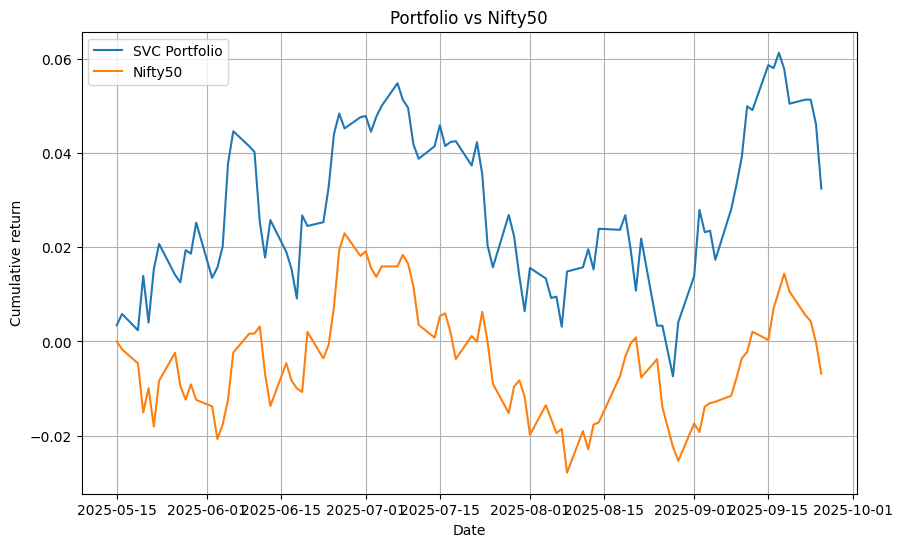

Portfolio final: 3.25%
Nifty final: -0.68%


In [33]:
index_prices = data[index_ticker].loc[common_index].dropna()
portfolio_cum = portfolio_cum.loc[index_prices.index]

index_cum = (index_prices / index_prices.iloc[0]) - 1

plt.figure(figsize=(10,6))
plt.plot(portfolio_cum.index, portfolio_cum.values, label='SVC Portfolio')
plt.plot(index_cum.index, index_cum.values, label='Nifty50')
plt.xlabel('Date'); plt.ylabel('Cumulative return')
plt.legend(); plt.grid(True)
plt.title('Portfolio vs Nifty50')
plt.show()

print("Portfolio final:", f"{portfolio_cum.iloc[-1]*100:.2f}%")
print("Nifty final:", f"{index_cum.iloc[-1]*100:.2f}%")

In [34]:
print("Date range of portfolio_cum:", portfolio_cum.index.min(), "to", portfolio_cum.index.max())
print("Date range of index_cum:", index_cum.index.min(), "to", index_cum.index.max())

Date range of portfolio_cum: 2025-05-15 00:00:00 to 2025-09-25 00:00:00
Date range of index_cum: 2025-05-15 00:00:00 to 2025-09-25 00:00:00


Save Results and Summaries

In [35]:
portfolio_cum.to_csv("svc_portfolio_cumulative.csv")

summary = []
for ticker, info in results_per_stock.items():
    strat_final = info['strat_cum'].iloc[-1]
    hold_final = info['hold_cum'].iloc[-1]
    acc = info['classification_report']['accuracy']
    summary.append([ticker, acc, strat_final, hold_final, info['test_len']])

summary_df = pd.DataFrame(summary, columns=['ticker','accuracy','strat_final','hold_final','test_len'])
summary_df.to_csv("per_stock_summary.csv", index=False)
print(summary_df)


          ticker  accuracy  strat_final  hold_final  test_len
0    RELIANCE.NS  0.526316    -0.024726   -0.052482        95
1   TATAPOWER.NS  0.610526     0.112176   -0.024320        95
2        SBIN.NS  0.484211     0.010476    0.087517        95
3   TATASTEEL.NS  0.473684     0.050473    0.121068        95
4   COALINDIA.NS  0.515789     0.038113   -0.002407        95
5         DLF.NS  0.547368     0.180013    0.024362        95
6        INFY.NS  0.515789    -0.069219   -0.066527        95
7          LT.NS  0.442105    -0.054211    0.016635        95
8   POWERGRID.NS  0.494737    -0.003393   -0.046789        95
9  BAJAJFINSV.NS  0.515789     0.047605   -0.002600        95


In [36]:
preds_df

,RELIANCE.NS,TATAPOWER.NS,SBIN.NS,TATASTEEL.NS,COALINDIA.NS,DLF.NS,INFY.NS,LT.NS,POWERGRID.NS,BAJAJFINSV.NS
Date,,,,,,,,,,
2025-05-15,0,1,1,0,1,1,0,1,1,1
2025-05-16,0,1,1,0,1,1,1,1,0,1
2025-05-19,0,1,1,0,1,1,1,1,0,1
2025-05-20,0,0,1,0,0,1,1,1,0,1
2025-05-21,0,1,1,0,0,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
2025-09-19,1,0,0,0,1,1,1,1,1,1
2025-09-22,1,0,0,1,1,1,1,1,1,1
2025-09-23,1,0,0,1,1,0,1,1,1,1


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

PARAMETERS & STOCK LIST

In [ ]:
stocks = [
    'RELIANCE.NS',   # Energy / Oil
    'TATAPOWER.NS',  # Power / Renewable
    'SBIN.NS',       # Banking
    'TATASTEEL.NS',  # Metals
    'COALINDIA.NS',  # Commodities / Mining
    'DLF.NS',        # Real estate
    'INFY.NS',       # IT / Software
    'LT.NS',         # Manufacturing / Engineering (Larsen & Toubro)
    'POWERGRID.NS',  # Power transmission
    'BAJAJFINSV.NS'  # NBFC / Financials
]

Download Close Prices

In [ ]:
raw = yf.download(stocks, start='2023-09-28', end='2025-09-28', progress=False)
# Use only 'Close'
if 'Close' in raw.columns:
    prices = raw['Close'].copy()
else:
    # yfinance sometimes returns a single-level DataFrame
    # raw may already be close-only
    prices = raw.copy()

prices = prices.sort_index()
print("Downloaded price shape:", prices.shape)

Downloaded price shape: (494, 10)


In [ ]:
prices.head()

Ticker,BAJAJFINSV.NS,COALINDIA.NS,DLF.NS,INFY.NS,LT.NS,POWERGRID.NS,RELIANCE.NS,SBIN.NS,TATAPOWER.NS,TATASTEEL.NS
Date,,,,,,,,,,
2023-09-28,1537.979858,250.990295,513.389404,1366.150024,2958.927490,186.380127,1158.475586,568.798706,255.357529,121.463135
2023-09-29,1538.529297,255.314697,524.050049,1362.353760,2972.247559,185.451706,1163.885620,577.090332,259.563171,123.474739
2023-10-03,1559.306030,252.460602,531.798828,1360.977661,3021.104248,185.266022,1150.559082,581.332581,261.196014,122.612625
2023-10-04,1530.837891,249.044312,518.966553,1370.800537,2976.376221,184.755386,1148.573853,565.231323,253.972137,120.026268
2023-10-05,1540.826782,250.255096,518.226196,1388.927979,3043.517334,182.527191,1148.549072,570.919800,255.110138,119.978371


**Part 2) i) For the above 10 stocks, use ARIMA with seasonality called SARIMAX to predict the stock
prices of each stock.**

**ii) Use support vector regression (SVR) to predict the stock price of each stock.**

**iii) Use XGBoost to predict the price of each stock.**

**(All answers below.)**

In [ ]:
def create_lag_features(series: pd.Series, n_lags=5):
    """
    Build a DataFrame with columns lag_1 ... lag_n and target = price next day.
    Example: lag_1 is price at t-1, target is price at t (shifted -1).
    """
    df = pd.DataFrame(series).rename(columns={series.name: 'price'})
    for lag in range(1, n_lags+1):
        df[f'lag_{lag}'] = df['price'].shift(lag)
    df['target'] = df['price'].shift(-1)   # next-day price
    df = df.dropna()
    return df

Containers for results

In [ ]:
results = {}   # per ticker store predictions & metrics

Loop through stocks

In [ ]:
for ticker in stocks:
    if ticker not in prices.columns:
        print("No data for", ticker, " — skipping")
        continue

    series = prices[ticker].dropna()
    if len(series) < 200:
        print("Too little data for", ticker, " — skipping")
        continue

    # Time-based train/test split (80/20)
    split_idx = int(len(series) * 0.8)
    train_series = series.iloc[:split_idx]
    test_series = series.iloc[split_idx:]

    # --- A: SARIMAX (simple seasonal choice)
    # We pick a simple model: order=(1,1,1), seasonal_order=(1,1,1,5)
    # seasonal period m=5 approximates weekly seasonality (5 trading days).
    try:
        # Reset index for SARIMAX
        sar_model = SARIMAX(train_series.reset_index(drop=True),
                            order=(1,1,1),
                            seasonal_order=(1,1,1,5),
                            enforce_stationarity=False,
                            enforce_invertibility=False)
        sar_res = sar_model.fit(disp=False)
        sar_fore = sar_res.get_forecast(steps=len(test_series)).predicted_mean
        # Set index back to test_series index
        sar_pred = pd.Series(sar_fore.values, index=test_series.index)
    except Exception as e:
        print("SARIMAX failed for", ticker, ":", e)
        sar_pred = pd.Series(index=test_series.index, dtype=float)

    # --- B,C: SVR and XGBoost using lag features
    df_lags = create_lag_features(series, n_lags=5)
    # Align train/test according to the same date split
    df_train = df_lags.loc[:train_series.index[-1]]
    df_test  = df_lags.loc[test_series.index[0]:]

    X_train = df_train[[f'lag_{i}' for i in range(1,6)]].values
    y_train = df_train['target'].values
    X_test = df_test[[f'lag_{i}' for i in range(1,6)]].values
    y_test = df_test['target'].values
    test_index = df_test.index

    # SVR pipeline (scale -> SVR)
    svr = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0, gamma='scale'))
    svr.fit(X_train, y_train)
    svr_pred_vals = svr.predict(X_test)
    svr_pred = pd.Series(svr_pred_vals, index=test_index)

    # XGBoost regressor (simple params)
    xgb = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42, verbosity=0)
    xgb.fit(X_train, y_train)
    xgb_pred_vals = xgb.predict(X_test)
    xgb_pred = pd.Series(xgb_pred_vals, index=test_index)

    # --- Metrics (compare predicted price vs actual test price y_test)
    def compute_metrics(true_vals, pred_vals):
        # Drop NaN values from both true_vals and pred_vals before computing metrics
        # Align indices and drop NaN values
        combined = pd.DataFrame({'true': true_vals, 'pred': pred_vals}).dropna()
        if combined.empty:
            return {'mse': np.nan, 'rmse': np.nan, 'mae': np.nan}

        mse = mean_squared_error(combined['true'], combined['pred'])
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(combined['true'], combined['pred'])
        return {'mse': mse, 'rmse': rmse, 'mae': mae}

    # Note: SARIMAX predictions index is test_series.index; for ML preds use df_test.index
    # For consistent comparison, only compare intersection of indices that exist for each method
    common_idx_sar = test_series.index.intersection(sar_pred.index)
    common_idx_svr = test_series.index.intersection(svr_pred.index)
    common_idx_xgb = test_series.index.intersection(xgb_pred.index)

    sar_metrics = compute_metrics(test_series.loc[common_idx_sar].values, sar_pred.loc[common_idx_sar].values) if len(common_idx_sar)>0 else {}
    svr_metrics = compute_metrics(series.loc[common_idx_svr].values, svr_pred.loc[common_idx_svr].values) if len(common_idx_svr)>0 else {}
    xgb_metrics = compute_metrics(series.loc[common_idx_xgb].values, xgb_pred.loc[common_idx_xgb].values) if len(common_idx_xgb)>0 else {}

    # Save everything
    results[ticker] = {
        'test_index': test_series.index,
        'test_actual': test_series,
        'sar_pred': sar_pred,
        'svr_pred': svr_pred,
        'xgb_pred': xgb_pred,
        'sar_metrics': sar_metrics,
        'svr_metrics': svr_metrics,
        'xgb_metrics': xgb_metrics
    }

    print(f"{ticker} done. Metrics (RMSE) -> SAR:{sar_metrics.get('rmse', np.nan):.3f}  SVR:{svr_metrics.get('rmse', np.nan):.3f}  XGB:{xgb_metrics.get('rmse', np.nan):.3f}")

RELIANCE.NS done. Metrics (RMSE) -> SAR:56.020  SVR:32.507  XGB:19.174
TATAPOWER.NS done. Metrics (RMSE) -> SAR:17.441  SVR:6.869  XGB:8.116
SBIN.NS done. Metrics (RMSE) -> SAR:27.848  SVR:26.080  XGB:12.083
TATASTEEL.NS done. Metrics (RMSE) -> SAR:18.771  SVR:3.695  XGB:2.984
COALINDIA.NS done. Metrics (RMSE) -> SAR:11.037  SVR:4.583  XGB:4.328
DLF.NS done. Metrics (RMSE) -> SAR:151.959  SVR:19.107  XGB:15.585
INFY.NS done. Metrics (RMSE) -> SAR:137.668  SVR:37.992  XGB:28.873
LT.NS done. Metrics (RMSE) -> SAR:149.310  SVR:102.582  XGB:47.753
POWERGRID.NS done. Metrics (RMSE) -> SAR:27.770  SVR:4.335  XGB:5.081
BAJAJFINSV.NS done. Metrics (RMSE) -> SAR:57.930  SVR:261.829  XGB:42.566


**Part 2) v) Discuss for which stocks SARIMAX or SVR or XGBoost is better in terms of mean square error
and other measurements.**

In [ ]:
summary = []
for t, info in results.items():
    sar_rmse = info['sar_metrics'].get('rmse', np.nan)
    svr_rmse = info['svr_metrics'].get('rmse', np.nan)
    xgb_rmse = info['xgb_metrics'].get('rmse', np.nan)
    sar_mae = info['sar_metrics'].get('mae', np.nan)
    svr_mae = info['svr_metrics'].get('mae', np.nan)
    xgb_mae = info['xgb_metrics'].get('mae', np.nan)

    best_rmse = 'SARIMAX' if sar_rmse == min([sar_rmse, svr_rmse, xgb_rmse]) else ('SVR' if svr_rmse == min([sar_rmse, svr_rmse, xgb_rmse]) else 'XGBoost')
    best_mae = 'SARIMAX' if sar_mae == min([sar_mae, svr_mae, xgb_mae]) else ('SVR' if svr_mae == min([sar_mae, svr_mae, xgb_mae]) else 'XGBoost')

    summary.append([t, sar_rmse, svr_rmse, xgb_rmse, best_rmse, sar_mae, svr_mae, xgb_mae, best_mae])

summary_df = pd.DataFrame(summary, columns=['ticker', 'sar_rmse', 'svr_rmse', 'xgb_rmse', 'best_by_rmse', 'sar_mae', 'svr_mae', 'xgb_mae', 'best_by_mae'])
print("\nSummary:")
display(summary_df)


Summary:


,ticker,sar_rmse,svr_rmse,xgb_rmse,best_by_rmse,sar_mae,svr_mae,xgb_mae,best_by_mae
0,RELIANCE.NS,56.020001,32.506538,19.174154,XGBoost,47.269606,23.012904,15.486894,XGBoost
1,TATAPOWER.NS,17.441139,6.868877,8.115936,SVR,14.470243,5.573892,6.246164,SVR
2,SBIN.NS,27.848331,26.079908,12.083021,XGBoost,24.107214,20.272612,8.966320,XGBoost
3,TATASTEEL.NS,18.770566,3.694561,2.983821,XGBoost,18.071428,2.825930,2.266057,XGBoost
4,COALINDIA.NS,11.036787,4.583260,4.327936,XGBoost,9.043676,3.562703,3.526393,XGBoost
5,DLF.NS,151.958894,19.106702,15.584876,XGBoost,144.605944,14.683455,11.643988,XGBoost
6,INFY.NS,137.668394,37.992309,28.873382,XGBoost,128.875506,29.060035,22.429090,XGBoost
7,LT.NS,149.310485,102.582296,47.752600,XGBoost,133.912977,90.362426,38.275839,XGBoost
8,POWERGRID.NS,27.770185,4.334824,5.080948,SVR,24.676343,3.490751,4.229390,SVR
9,BAJAJFINSV.NS,57.929782,261.829314,42.566003,XGBoost,45.736317,255.897855,35.438884,XGBoost


**Part 2) iv) Plot the actual stock price versus the predicted stock price with those from SARIMAX and SVR and XGBoost.**

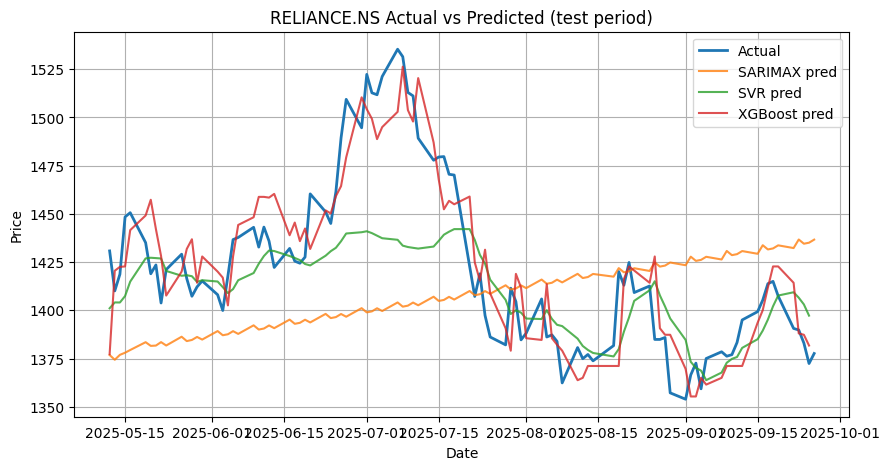

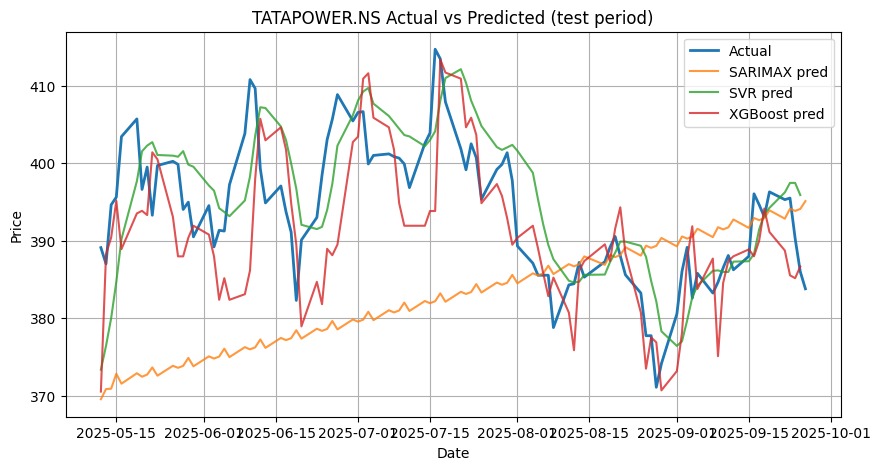

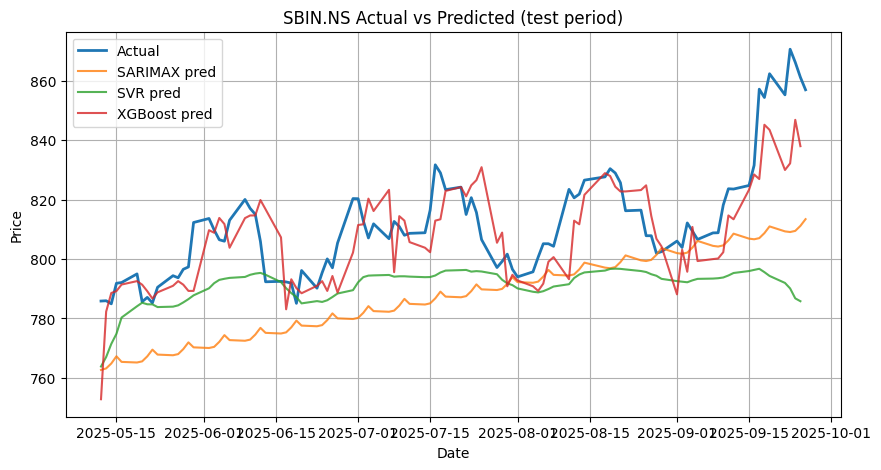

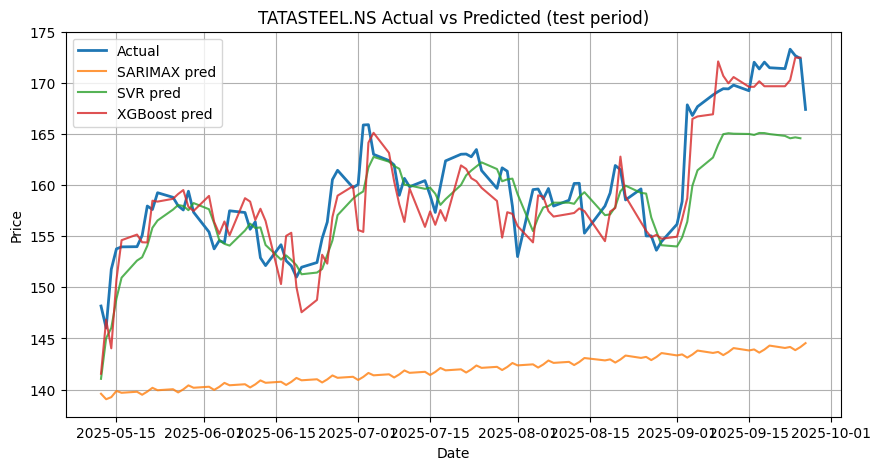

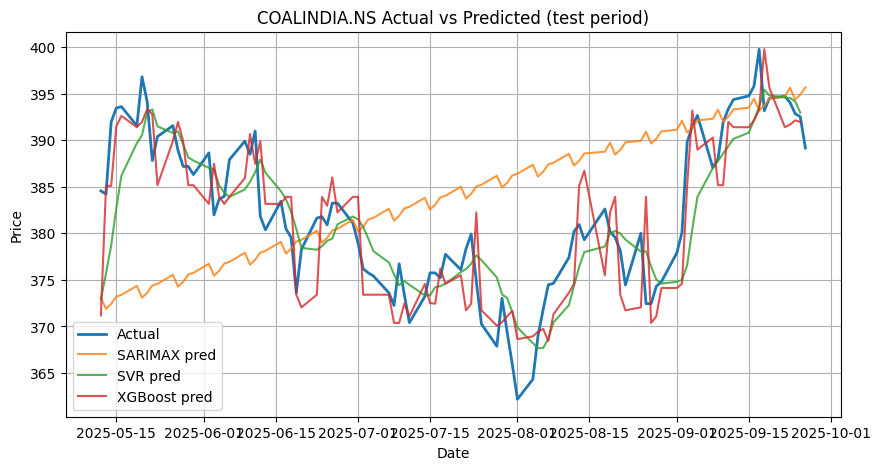

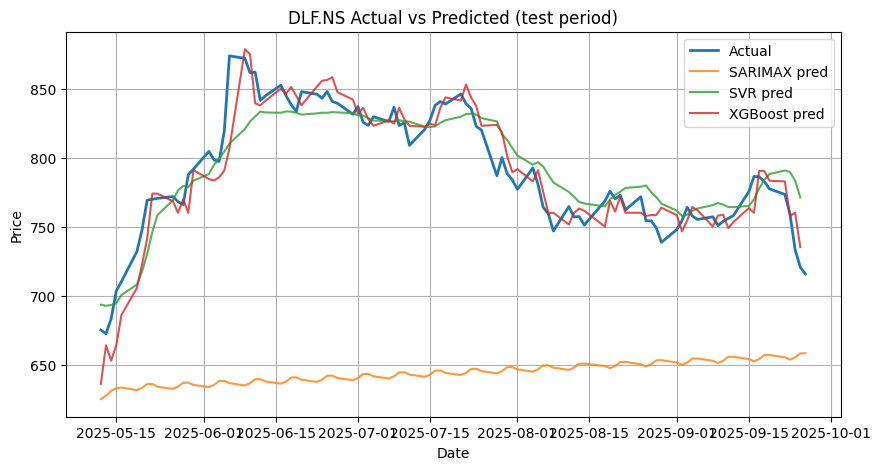

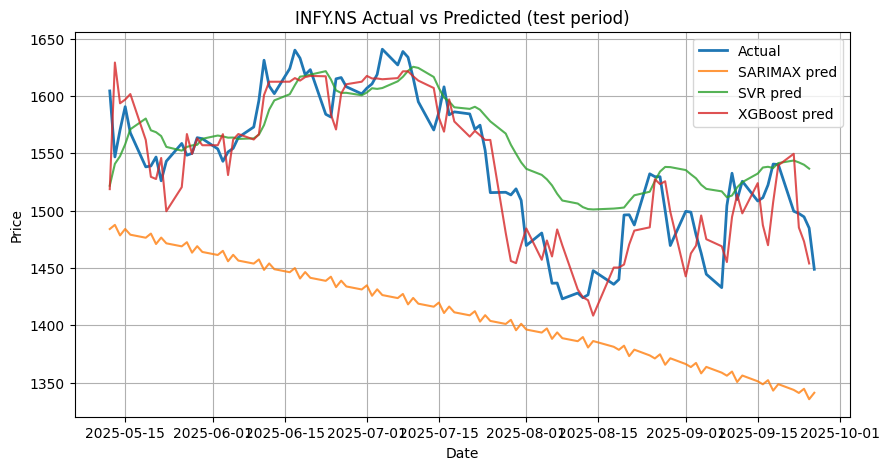

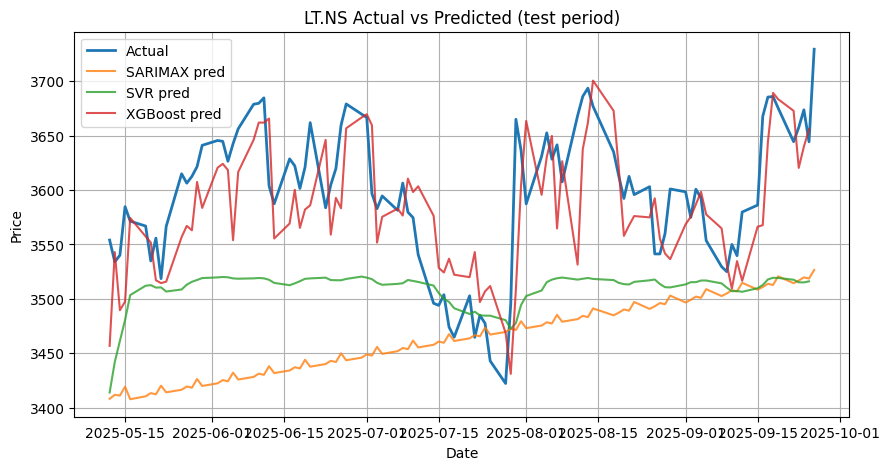

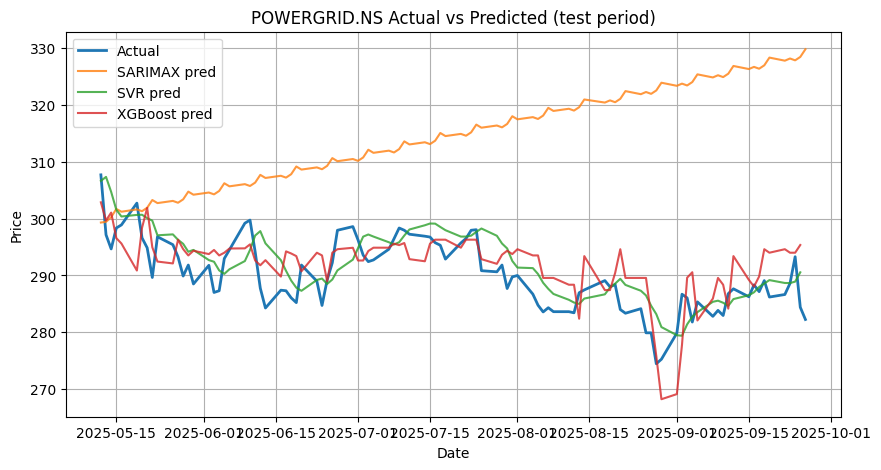

In [ ]:
for i in range(0,9):
  example = list(results.keys())[i]
  info = results[example]
  plt.figure(figsize=(10,5))
  plt.plot(info['test_actual'].index, info['test_actual'].values, label='Actual', linewidth=2)
  if not info['sar_pred'].empty:
      plt.plot(info['sar_pred'].index, info['sar_pred'].values, label='SARIMAX pred', alpha=0.8)
  plt.plot(info['svr_pred'].index, info['svr_pred'].values, label='SVR pred', alpha=0.8)
  plt.plot(info['xgb_pred'].index, info['xgb_pred'].values, label='XGBoost pred', alpha=0.8)
  plt.title(f"{example} Actual vs Predicted (test period)")
  plt.xlabel("Date"); plt.ylabel("Price")
  plt.legend(); plt.grid(True); plt.show()

**Part 2) vi) Try another ML techniques like ARIMA-ANN or SARIMA-SVR or any other technique you would like to explore on any one of the 10 stocks and compare with previous predictions.**

Data loaded: 2023-09-28 00:00:00 → 2025-09-26 00:00:00 (522 rows)
Train size: 432, Test size: 90


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut


Performance on test set:
            Model       RMSE        MAE
0        SARIMAX  61.508761  52.991090
1  SARIMAX + SVR  61.198653  52.734065


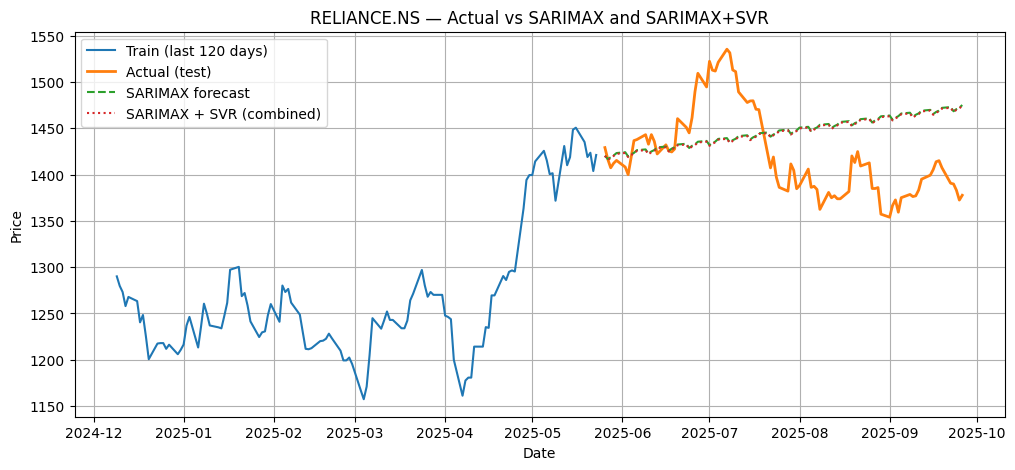

In [24]:
# Hybrid SARIMAX + SVR Forecasting using pre-loaded data

# Assuming 'prices' DataFrame exists from earlier steps
ticker_to_analyze = 'RELIANCE.NS' # Or any other ticker from your list
if ticker_to_analyze not in prices.columns:
    print(f"Ticker {ticker_to_analyze} not found in downloaded data. Please check the ticker list.")
else:
    series = prices[ticker_to_analyze].dropna()

    # Resample to business days (forward-fill missing)
    series = series.asfreq('B', method='pad').dropna()

    print("Data loaded:", series.index.min(), "→", series.index.max(), f"({len(series)} rows)")


    # 3. Train-test split

    n = len(series)
    test_days = 90 if n > 450 else max(int(n*0.2), 30)

    train = series.iloc[:-test_days]
    test = series.iloc[-test_days:]
    print(f"Train size: {len(train)}, Test size: {len(test)}")


    # 4. Fit SARIMAX model

    order = (1, 1, 1)
    seasonal_order = (1, 1, 1, 5)   # weekly-ish seasonality (can be tuned)

    sarima_model = SARIMAX(
        train, order=order, seasonal_order=seasonal_order,
        enforce_stationarity=False, enforce_invertibility=False
    )
    sarima_res = sarima_model.fit(disp=False)

    sar_pred = sarima_res.get_forecast(steps=len(test))
    sar_pred_mean = sar_pred.predicted_mean
    sar_pred_mean.index = test.index


    # 5. Train SVR on SARIMA residuals

    train_fitted = sarima_res.fittedvalues
    residuals = (train - train_fitted).dropna()

    # Create lagged residual features
    def make_lagged(series, lags=5):
        X = pd.DataFrame({f"lag_{i}": series.shift(i) for i in range(1, lags+1)})
        return X.dropna()

    lags = 5
    X_res = make_lagged(residuals, lags=lags)
    y_res = residuals.loc[X_res.index]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_res)

    svr = SVR(kernel='rbf', C=1.0, epsilon=0.01)
    svr.fit(X_scaled, y_res.values.ravel())


    # 6. Recursive prediction of residuals

    combined_pred = sar_pred_mean.copy()
    residuals_full = residuals.copy()

    for idx in combined_pred.index:
        last = residuals_full.iloc[-lags:]
        if len(last) < lags:
            pad = pd.Series([0.0] * (lags - len(last)))
            last_vals = pd.concat([pad, last]).values
        else:
            last_vals = last.values

        lag_vec = last_vals[::-1]  # reverse: lag_1 = most recent
        X_pred_scaled = scaler.transform(lag_vec.reshape(1, -1))
        res_pred = svr.predict(X_pred_scaled)[0]

        residuals_full.loc[idx] = res_pred
        combined_pred.loc[idx] = combined_pred.loc[idx] + res_pred


    # 7. Evaluate performance

    def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

    metrics = pd.DataFrame({
        "Model": ["SARIMAX", "SARIMAX + SVR"],
        "RMSE": [rmse(test.values, sar_pred_mean.values),
                 rmse(test.values, combined_pred.values)],
        "MAE": [mean_absolute_error(test.values, sar_pred_mean.values),
                mean_absolute_error(test.values, combined_pred.values)]
    })
    print("\nPerformance on test set:\n", metrics)


    # 8. Plot results

    plt.figure(figsize=(12, 5))
    plt.plot(train.index[-120:], train.values[-120:], label="Train (last 120 days)")
    plt.plot(test.index, test.values, label="Actual (test)", linewidth=2)
    plt.plot(sar_pred_mean.index, sar_pred_mean.values, label="SARIMAX forecast", linestyle="--")
    plt.plot(combined_pred.index, combined_pred.values, label="SARIMAX + SVR (combined)", linestyle=":")
    plt.xlabel("Date"); plt.ylabel("Price")
    plt.title(f"{ticker_to_analyze} — Actual vs SARIMAX and SARIMAX+SVR")
    plt.legend(); plt.grid(True)
    plt.show()